In [1]:
import rasterio
import matplotlib.pyplot as plt
import glob
import subprocess

In [2]:
city_DEM_dirs = sorted(glob.glob("/glade/derecho/scratch/jstarfeldt/uhminicubes/hresgrid/NASADEM/*"))

In [3]:
elevation_datas = []

for city_dir in city_DEM_dirs:
    #print(city_dir)
    for file in glob.glob(city_dir+'/*'):
        # Simply point to the .bil file (rasterio will read the .hdr automatically)
        subfile = file.split('_')[-1]
        hgt_file = f'{file}/{subfile}.hgt'

        with rasterio.open(hgt_file) as src:
            profile = src.profile

            # Update the file format driver to GeoTIFF
            profile.update(driver="GTiff")

            # Write out the new file
            new_dir = city_dir.replace('NASADEM', 'NASADEM_geotiff')
            subprocess.run(['mkdir', '-p', new_dir])
            with rasterio.open(f'{new_dir}/{subfile}.tif', "w", **profile) as dst:
                dst.write(src.read())

            # Read the elevation grid into a standard NumPy array
            elevation_data = src.read(1)
            elevation_datas.append(elevation_data)

            # Access geospatial metadata
            #print(f"Dimensions: {src.width}x{src.height}")
            #print(f"Coordinate Reference System: {src.crs}")
            #print(f"Bounding Box: {src.bounds}")
    #print()

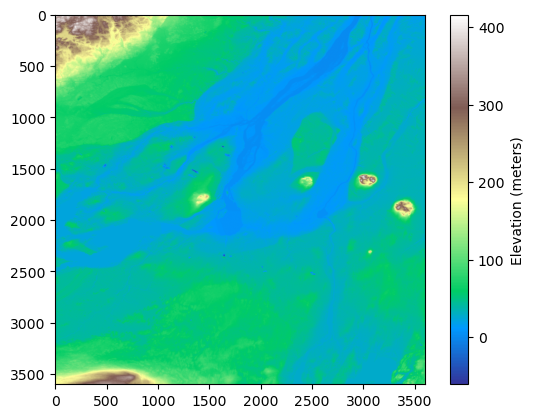

In [4]:
# Plot the elevation data visually
plt.imshow(elevation_datas[0], cmap='terrain')
plt.colorbar(label='Elevation (meters)')
plt.show()